In [1]:
# --------------------------------------------------------------------------
# 0. Libraries and Reproducibility
# --------------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, skew
from scipy.optimize import minimize
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
warnings.filterwarnings("ignore", category=Warning, module="sklearn.gaussian_process")

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# --------------------------------------------------------------------------
# 1. Data  
# --------------------------------------------------------------------------
X = np.load('..\Function_3_Data\Week_9_Data/F3_Week_9_inputs.npy')
y = np.load('..\Function_3_Data\Week_9_Data/F3_Week_9_outputs.npy')
n, d = X.shape
print(f"n = {n} observations, d = {d} input dimensions  (was n=21 in v1)")
BOUNDS = np.array([[0.0, 1.0]] * d)

n = 23 observations, d = 3 input dimensions  (was n=21 in v1)



New incumbent (best observed over all 23 points): x*=[0.46   0.5709 0.4265], y*=-0.00817  (row index 21)
Previous incumbent was    : x*=[0.447851 0.552632 0.391512], y*=-0.01230


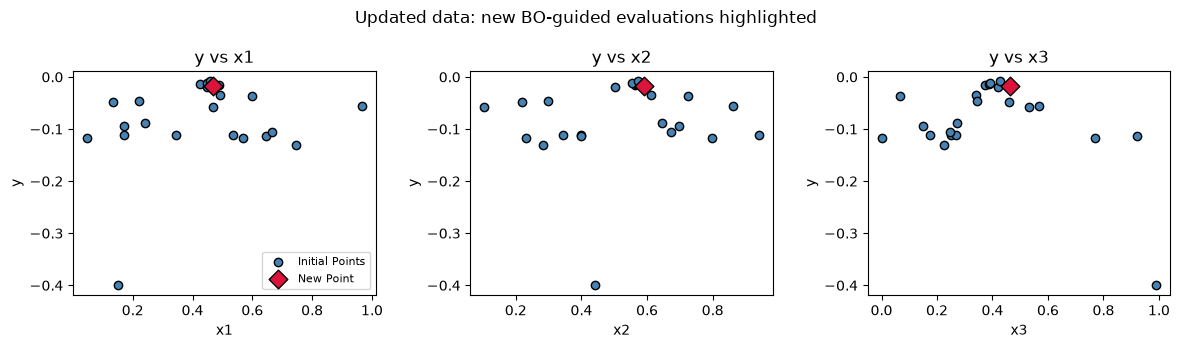

In [3]:
# --------------------------------------------------------------------------
# 2. Comparison with the last week's query
# --------------------------------------------------------------------------
prev_incumbent_x = np.array([0.447851, 0.552632, 0.391512])
prev_recommended_x = np.array([0.4600, 0.5709, 0.4265])

best_idx = np.argmax(y)
x_best, y_best = X[best_idx], y[best_idx]
print(f"\nNew incumbent (best observed over all {n} points): "
      f"x*={np.round(x_best,4)}, y*={y_best:.5f}  (row index {best_idx})")
print(f"Previous incumbent was    : x*={prev_incumbent_x}, y*=-0.01230")


fig, axes = plt.subplots(1, d, figsize=(4 * d, 3.5))
for i in range(d):
    axes[i].scatter(X[:-1, i], y[:-1], c="steelblue", edgecolor="k", label="Initial Points")
    axes[i].scatter(X[-1:, i], y[-1:], c="crimson", edgecolor="k", s=90, marker="D",
                     label="New Point", zorder=5)
    axes[i].set_xlabel(f"x{i+1}")
    axes[i].set_ylabel("y")
    axes[i].set_title(f"y vs x{i+1}")
    if i == 0:
        axes[i].legend(fontsize=8)
fig.suptitle("Updated data: new BO-guided evaluations highlighted")
fig.tight_layout()

Target Transformation Check on all points
raw y   : skew=-2.631, range=0.3908
g=-log(-y): skew=0.259, range=3.8881


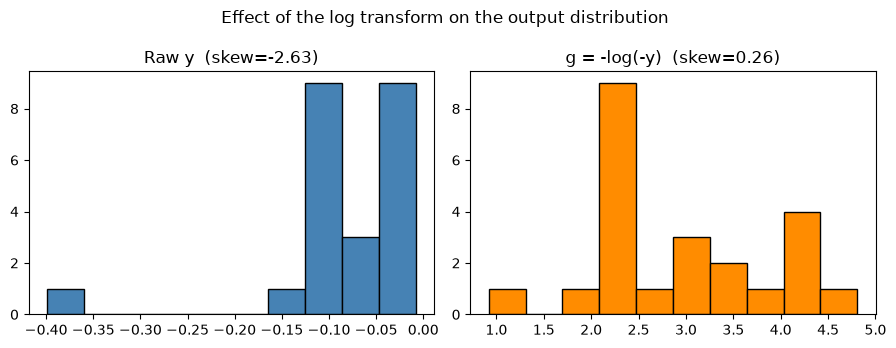

In [4]:
# --------------------------------------------------------------------------
# 3. Output transformation (unchanged rationale, re-applied)
# --------------------------------------------------------------------------
# Still strictly negative outputs, still one severe outlier (-0.399) far from
# everything else, so g(x) = -log(-y(x)) still applies unchanged. 

g = -np.log(-y)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].hist(y, bins=10, color="steelblue", edgecolor="k")
axes[0].set_title(f"Raw y  (skew={skew(y):.2f})")
axes[1].hist(g, bins=10, color="darkorange", edgecolor="k")
axes[1].set_title(f"g = -log(-y)  (skew={skew(g):.2f})")
fig.suptitle("Effect of the log transform on the output distribution")
fig.tight_layout()

print("=" * 100)
print("Target Transformation Check on all points")
print("=" * 100)
print(f"raw y   : skew={skew(y):.3f}, range={y.max()-y.min():.4f}")
print(f"g=-log(-y): skew={skew(g):.3f}, range={g.max()-g.min():.4f}")
g_best = g[best_idx]



In [5]:
# --------------------------------------------------------------------------
# 4. Surrogate model: Gaussian Process Matern 5/2 ARD with WhiteKernel
# --------------------------------------------------------------------------

def make_gp(ard: bool, n_dims: int, seed: int) -> GaussianProcessRegressor:
    length_scale = np.ones(n_dims) if ard else 1.0
    kernel = (
        ConstantKernel(1.0, (1e-2, 1e2))
        * Matern(length_scale=length_scale, length_scale_bounds=(1e-2, 1e2), nu=2.5)
        + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-8, 3e-1))
    )
    return GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=20,
        random_state=seed,
    )

def loo_cv(ard: bool, X, g, seed):
    n = len(g)
    sq_err = np.zeros(n)
    nlpd = np.zeros(n)
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        gp = make_gp(ard, X.shape[1], seed)
        gp.fit(X[mask], g[mask])
        mu, std = gp.predict(X[i:i+1], return_std=True)
        mu, std = mu[0], max(std[0], 1e-6)
        sq_err[i] = (mu - g[i]) ** 2
        nlpd[i] = 0.5 * np.log(2 * np.pi * std**2) + 0.5 * ((g[i] - mu) ** 2) / std**2
    return np.sqrt(sq_err.mean()), nlpd.mean()

print("=" * 100)
print("Model selection RE-RUN on all pointsá: isotropic vs ARD (leave-one-out CV)")
print("=" * 100)

results = {}
for ard in (False, True):
    rmse, nlpd = loo_cv(ard, X, g, SEED)
    gp_full = make_gp(ard, d, SEED).fit(X, g)
    lml = gp_full.log_marginal_likelihood(gp_full.kernel_.theta)
    results[ard] = (rmse, nlpd, lml, gp_full)
    tag = "ARD      " if ard else "Isotropic"
    print(f"{tag}: LOO-RMSE(g)={rmse:.4f}  LOO-NLPD={nlpd:.4f}  train LML={lml:.3f}")
    print(f"           fitted kernel: {gp_full.kernel_}")

use_ard = results[True][1] < results[False][1]
print(f"\n=> Selected model: {'ARD' if use_ard else 'Isotropic'} "
      "(lower leave-one-out NLPD; RMSE used as a tie-breaker)")

gp = results[use_ard][3]
print("\nFitted hyperparameters of the chosen GP:")
print(gp.kernel_)


Model selection RE-RUN on all pointsá: isotropic vs ARD (leave-one-out CV)
Isotropic: LOO-RMSE(g)=0.7088  LOO-NLPD=1.1415  train LML=-24.516
           fitted kernel: 0.831**2 * Matern(length_scale=0.0835, nu=2.5) + WhiteKernel(noise_level=1e-08)
ARD      : LOO-RMSE(g)=0.6657  LOO-NLPD=20.1541  train LML=-20.371
           fitted kernel: 0.986**2 * Matern(length_scale=[100, 0.671, 0.0964], nu=2.5) + WhiteKernel(noise_level=0.0488)

=> Selected model: Isotropic (lower leave-one-out NLPD; RMSE used as a tie-breaker)

Fitted hyperparameters of the chosen GP:
0.831**2 * Matern(length_scale=0.0835, nu=2.5) + WhiteKernel(noise_level=1e-08)


In [6]:
# --------------------------------------------------------------------------
# 5. Acquisition function: Expected Improvement
# --------------------------------------------------------------------------
XI=0.02
def expected_improvement(Xcand, gp, g_best, xi=XI):
    mu, sigma = gp.predict(Xcand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    z = (mu - g_best - xi) / sigma
    ei = (mu - g_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

In [7]:
# --------------------------------------------------------------------------
# 6. Optimising the acquisition function -> next query point
# --------------------------------------------------------------------------
def propose_next(gp, g_best, bounds, n_restarts=50, seed=SEED):
    rng = np.random.default_rng(seed)
    dim = bounds.shape[0]
    best_x, best_val = None, -np.inf

    def neg_ei(x):
        return -expected_improvement(x.reshape(1, -1), gp, g_best)[0]

    starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(n_restarts, dim))
    for x0 in starts:
        res = minimize(neg_ei, x0, bounds=bounds, method="L-BFGS-B")
        if -res.fun > best_val:
            best_val, best_x = -res.fun, res.x
    return best_x, best_val

x_next, ei_next = propose_next(gp, g_best, BOUNDS)
mu_next, std_next = gp.predict(x_next.reshape(1, -1), return_std=True)

print("=" * 100)
print("Next recommended query point")
print("=" * 100)
print(f"x_next = {np.round(x_next, 6)}")
print(f"EI(x_next) = {ei_next:.5f}   posterior mean g = {mu_next[0]:.4f} "
      f"+/- {std_next[0]:.4f}")



Next recommended query point
x_next = [0.48116  0.55917  0.424929]
EI(x_next) = 0.03032   posterior mean g = 4.6826 +/- 0.2091


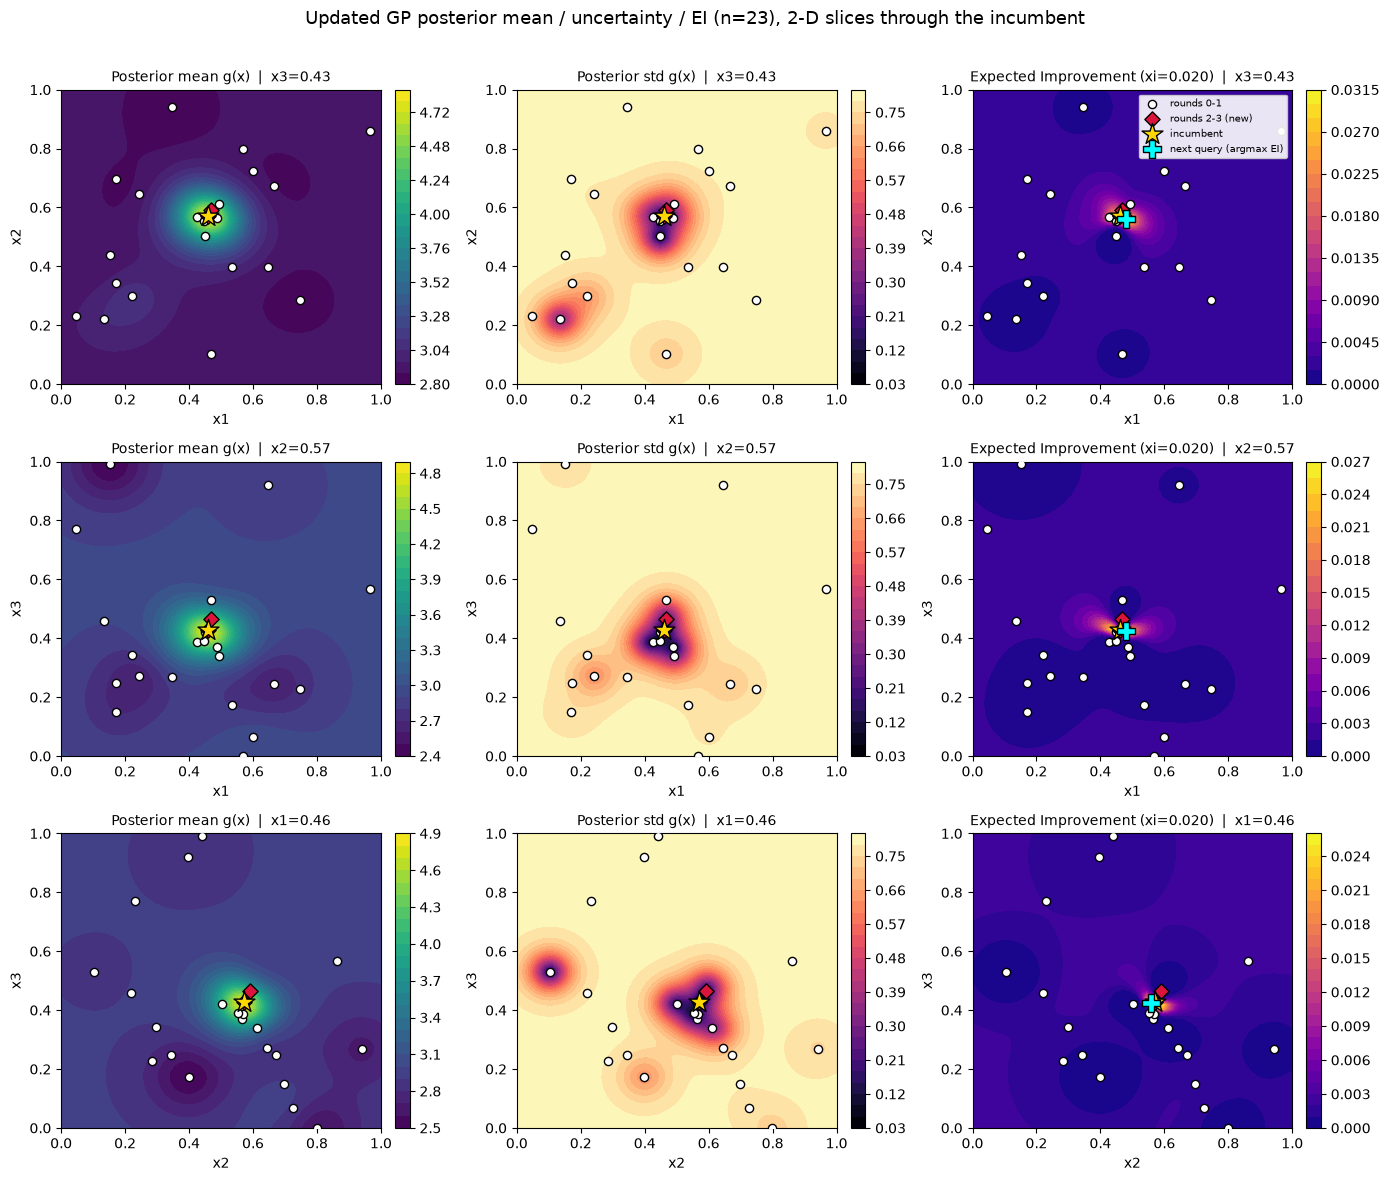

In [8]:
# --------------------------------------------------------------------------
# 7. Plots
# --------------------------------------------------------------------------
grid_n = 80
lin = np.linspace(0, 1, grid_n)
dim_names = ["x1", "x2", "x3"]
pairs = [(0, 1), (0, 2), (1, 2)]

fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for row, (i, j) in enumerate(pairs):
    k = [a for a in range(3) if a not in (i, j)][0]
    fixed_val = x_best[k]

    A, B = np.meshgrid(lin, lin)
    grid = np.zeros((grid_n * grid_n, 3))
    grid[:, i] = A.ravel()
    grid[:, j] = B.ravel()
    grid[:, k] = fixed_val

    mu, std = gp.predict(grid, return_std=True)
    ei = expected_improvement(grid, gp, g_best)

    mu_grid = mu.reshape(grid_n, grid_n)
    std_grid = std.reshape(grid_n, grid_n)
    ei_grid = ei.reshape(grid_n, grid_n)

    for col, (Z, title, cmap) in enumerate([
        (mu_grid, f"Posterior mean g(x)  |  {dim_names[k]}={fixed_val:.2f}", "viridis"),
        (std_grid, f"Posterior std g(x)  |  {dim_names[k]}={fixed_val:.2f}", "magma"),
        (ei_grid, f"Expected Improvement (xi={XI:.3f})  |  {dim_names[k]}={fixed_val:.2f}", "plasma"),
    ]):
        ax = axes[row, col]
        cf = ax.contourf(A, B, Z, levels=25, cmap=cmap)
        fig.colorbar(cf, ax=ax, fraction=0.046, pad=0.04)
        ax.scatter(X[:-2, i], X[:-2, j], c="white", edgecolor="black", s=35, zorder=3,
                   label="rounds 0-1")
        ax.scatter(X[-2:, i], X[-2:, j], c="crimson", edgecolor="black", s=60,
                   marker="D", zorder=4, label="rounds 2-3 (new)")
        ax.scatter(x_best[i], x_best[j], marker="*", c="gold", s=250,
                   edgecolor="black", zorder=5, label="incumbent")
        if col == 2:
            ax.scatter(x_next[i], x_next[j], marker="P", c="cyan", s=180,
                       edgecolor="black", zorder=5, label="next query (argmax EI)")
        ax.set_xlabel(dim_names[i])
        ax.set_ylabel(dim_names[j])
        ax.set_title(title, fontsize=10)
        if row == 0 and col == 2:
            ax.legend(loc="upper right", fontsize=7, framealpha=0.9)

fig.suptitle("Updated GP posterior mean / uncertainty / EI (n=23), 2-D slices through the incumbent",
             fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97])

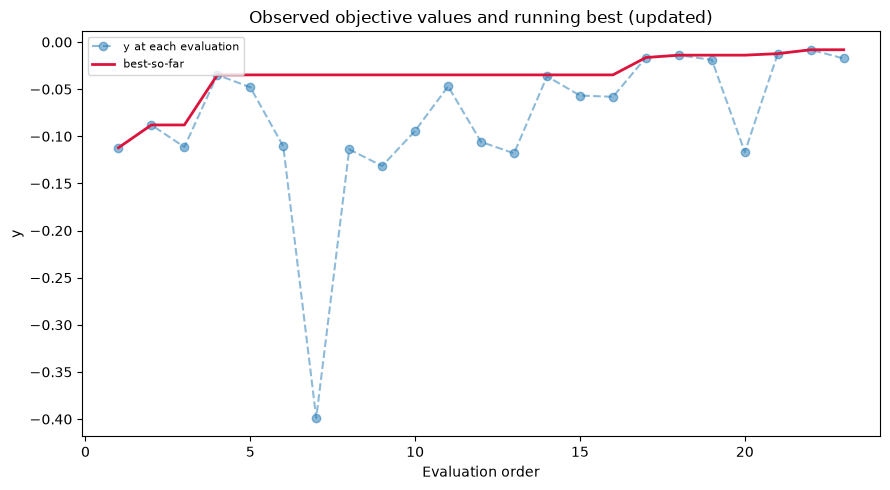

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
running_best = np.maximum.accumulate(y)
ax.plot(range(1, n + 1), y, "o--", alpha=0.5, label="y at each evaluation")
ax.plot(range(1, n + 1), running_best, "-", lw=2, color="crimson", label="best-so-far")
# ax.axvspan(21.5, n + 0.5, color="crimson", alpha=0.08, label="rounds 2-3 (new)")
ax.set_xlabel("Evaluation order")
ax.set_ylabel("y")
ax.set_title("Observed objective values and running best (updated)")
ax.legend(fontsize=8)
fig.tight_layout()